# AI Service-Desk Ticket Triage: Proof of Concept for Cybit
**AI/ML Engineer Intern assessment.** Pipeline: ticket → category + priority → knowledge-base retrieval → grounded draft reply → routing with safety guardrails.

Cybit's real tickets are private, so training data is **synthetic**. Scores on synthetic data overstate real performance; the notebook also reports a hand-written *dev set* and a *blind test set* to show the gap honestly.

Run all cells top to bottom (about 1 minute, no GPU needed).

In [1]:
!pip -q install scikit-learn scipy numpy pandas matplotlib anthropic

In [ ]:
%%writefile kb_and_data.py

import random

CATEGORIES = ["account_access", "email_m365", "network_vpn", "hardware", "software",
              "security_incident", "cloud_azure", "backup_storage", "printing", "data_bi"]
PRIORITIES = ["P1", "P2", "P3", "P4"]

# ---------------------------------------------------------------- knowledge base
KB = [
 ("KB-001","account_access","Password reset and account lockout","1) Confirm the user's identity via the approved verification steps. 2) Unlock the account in Entra ID / Active Directory. 3) Issue a temporary password and force change at next sign-in. 4) Check for repeated lockouts from an old phone or mapped drive using stale credentials."),
 ("KB-002","account_access","MFA reset and new device enrolment","1) Verify identity. 2) In Entra ID > Authentication methods, require re-register MFA. 3) User signs in and registers Microsoft Authenticator on the new phone. 4) Remove the old device from the user's registered methods."),
 ("KB-003","email_m365","Outlook not syncing or profile corrupt","1) Check Microsoft 365 service health. 2) Run Outlook in safe mode and disable add-ins. 3) Remove and re-add the mail profile. 4) Rebuild the OST file. 5) If only one mailbox is affected, check mailbox size and licence."),
 ("KB-004","email_m365","Missing email, quarantine and mail flow","1) Run a message trace in Exchange admin centre. 2) Check Defender quarantine and release if legitimate. 3) Review inbox rules and forwarding. 4) Verify SPF, DKIM and DMARC if external senders are affected. 5) Check shared mailbox permissions."),
 ("KB-005","network_vpn","VPN will not connect","1) Confirm the user's internet connection and credentials. 2) Check the VPN gateway status and licence/user limit on the firewall. 3) Reinstall or update the VPN client. 4) Check MFA prompt delivery. 5) Review firewall logs for blocked or geo-blocked attempts."),
 ("KB-006","network_vpn","Network or Wi-Fi drops, slow or no connectivity","1) Identify scope: one user, one site, or all sites. 2) Check switch and access point status in the monitoring tool. 3) Test DNS and DHCP. 4) Check ISP circuit and failover link. 5) If a site is down, escalate to the network team immediately."),
 ("KB-007","hardware","Laptop slow, freezing or will not boot","1) Check disk space, CPU and memory in Task Manager. 2) Apply pending Windows updates and restart. 3) Run hardware diagnostics. 4) Check disk health (SMART). 5) If failing, arrange a loan device and re-image."),
 ("KB-008","hardware","Monitor, docking station or headset not working","1) Reseat cables and test another port. 2) Update dock and graphics drivers. 3) Test with a known-good peripheral. 4) Raise a hardware replacement through the supplier if faulty."),
 ("KB-009","software","Software installation or access request","1) Check the request has manager approval. 2) Confirm a licence is available. 3) Deploy via Intune / Software Centre. 4) Add the user to the correct application group. 5) Confirm with the user and close."),
 ("KB-010","software","Application crashing or licence not activating","1) Capture the error message and app version. 2) Repair or reinstall the application. 3) Clear the cached licence and sign in again. 4) Check the licence assignment in the admin portal. 5) Check compatibility after recent updates."),
 ("KB-011","security_incident","Reported phishing email","1) Do NOT click links or open attachments. 2) Have the user report it using the Report Message button. 3) Search the tenant for the same message and purge it. 4) Check whether anyone clicked or entered credentials; if so, reset the password and revoke sessions. 5) Notify the security team."),
 ("KB-012","security_incident","Suspected malware or ransomware","1) Isolate the device from the network immediately (do not power off if ransomware is suspected). 2) Escalate to the security operations team as a P1 incident. 3) Preserve logs and evidence. 4) Identify the scope using EDR. 5) Begin the incident response plan and notify the client's nominated contact."),
 ("KB-013","cloud_azure","Azure VM or web app unavailable","1) Check Azure Service Health for the region. 2) Check VM status, recent deployments and resource health. 3) Review the NSG and firewall rules for recent changes. 4) Restart the VM or app service if safe. 5) Escalate to the cloud team if production is affected."),
 ("KB-014","cloud_azure","Azure permissions, role access or cost alert","1) Identify the subscription and resource group. 2) Review role assignments (RBAC) and PIM eligibility. 3) For cost alerts, review Cost Analysis for the spike and look for idle or oversized resources. 4) Apply tags and budget alerts."),
 ("KB-015","backup_storage","Backup job failed","1) Check the backup console for the error code. 2) Verify agent status and free space on the target. 3) Check network connectivity to the repository. 4) Re-run the job manually. 5) If repeated failures, escalate as the client may have no valid recovery point."),
 ("KB-016","backup_storage","File restore or shared drive full","1) Confirm the file path and the date it was last good. 2) Restore from the backup or previous versions. 3) For a full drive, find the largest folders and archive or extend the volume. 4) Confirm the restore with the user."),
 ("KB-017","printing","Printer offline or print queue stuck","1) Check the printer is on the network and has a valid IP. 2) Clear the print queue and restart the Print Spooler service. 3) Reinstall the printer driver. 4) Check the print server status if multiple users are affected."),
 ("KB-018","printing","Scan to email or scan to folder failing","1) Check the SMTP relay settings and credentials on the device. 2) Verify the destination folder permissions. 3) Test with a different user. 4) Check the firewall is not blocking the SMTP relay."),
 ("KB-019","data_bi","Power BI dataset refresh failed","1) Open the refresh history and read the error. 2) Check data source credentials and gateway status. 3) Check source database availability. 4) Re-run the refresh. 5) If a schema changed, update the query in Power Query."),
 ("KB-020","data_bi","Power BI report access or gateway problem","1) Check the user's licence (Pro/PPU) and workspace role. 2) Share the report or app with the user's group. 3) Check the on-premises data gateway is online and updated. 4) Apply row-level security mapping if data is missing."),
]
KB_BY_ID = {k[0]: k for k in KB}

# symptom phrases (Testing purpose only not for the deployment )
SYMPTOMS = {
 "KB-001": ["I forgot my password and cannot log in", "my account is locked out again after the weekend", "password expired and the reset page gives an error", "keeps saying incorrect password but I know it is right"],
 "KB-002": ["got a new phone and the authenticator app no longer works", "not receiving the MFA code when signing in", "need my multi factor reset, old mobile was lost", "authenticator keeps asking for approval but nothing arrives"],
 "KB-003": ["outlook is stuck on updating inbox and wont sync", "outlook keeps crashing when I open it", "emails not coming through to outlook on my laptop but fine on phone", "outlook asking for password over and over"],
 "KB-004": ["an email from a customer never arrived, can you trace it", "emails going to junk or quarantine from a supplier", "cannot see the shared mailbox in outlook", "mail to external clients is bouncing back"],
 "KB-005": ["VPN wont connect from home", "vpn client says connection timed out", "cannot connect to the vpn since the update last night", "vpn connects then drops after a few minutes"],
 "KB-006": ["internet is very slow in the office", "wifi keeps dropping on the second floor", "no network connection on my desk port", "cannot reach any internal websites, dns issue maybe"],
 "KB-007": ["laptop is extremely slow and freezes", "laptop wont boot, stuck on the black screen", "pc keeps restarting by itself", "laptop battery drains in an hour and it gets hot"],
 "KB-008": ["second monitor not detected via the dock", "headset microphone not working in teams", "docking station not charging the laptop", "keyboard and mouse intermittently disconnecting"],
 "KB-009": ["please can you install Adobe Acrobat on my machine", "new starter needs access to the CRM and Visio", "request to install python for the data team", "need Project installed, manager has approved"],
 "KB-010": ["excel crashes every time I open a large file", "office says product not activated", "the accounting software throws an error on startup", "application will not launch after the latest windows update"],
 "KB-011": ["received a suspicious email asking me to confirm my bank details", "got an email that looks like phishing pretending to be the CEO", "clicked a link in an email and entered my password, now worried", "strange email with a zip attachment from unknown sender"],
 "KB-012": ["antivirus popup says malware detected on my laptop", "files have extensions changed and cant be opened, ransom note on desktop", "computer is showing lots of pop ups and running strangely, might be a virus", "EDR alert: unknown process encrypting files on server"],
 "KB-013": ["the azure web app is returning 503 errors", "our VM in azure is unreachable over RDP", "the customer portal hosted in azure is down", "azure app service keeps restarting"],
 "KB-014": ["I need contributor access to the azure subscription", "unexpected cost alert on our azure account this month", "cannot see the resource group in azure portal", "need to set up a budget alert in azure"],
 "KB-015": ["last night's backup failed with an error", "backup job has been failing for three days", "veeam reports a warning on the file server backup", "no successful backup recorded for the sql server"],
 "KB-016": ["I accidentally deleted a folder from the shared drive, can you restore it", "shared drive is full and no one can save files", "need to recover an old version of a spreadsheet", "restore request for the finance folder from last week"],
 "KB-017": ["printer shows offline", "print jobs stuck in the queue", "cannot print to the third floor printer", "printer prints blank pages"],
 "KB-018": ["scan to email stopped working on the copier", "scan to folder says access denied", "scanner sends nothing to my inbox", "multi function device cannot send scans"],
 "KB-019": ["power bi refresh failed this morning", "the sales dashboard has not updated since yesterday", "scheduled refresh error credentials invalid", "dataset refresh keeps timing out"],
 "KB-020": ["cannot open the power bi report, says no access", "gateway is offline in power bi", "numbers missing in the report for my region", "need access to the finance workspace in power bi"],
}

OPENERS = ["Hi,", "Hello team,", "Hi support,", "Good morning,", "Urgent:", "Hey,", "", "", "Hi there,", "Afternoon,", "Hello,"]
CLOSERS = ["Thanks", "Thanks in advance", "Please advise", "Cheers", "Regards", "", "", "Let me know", "Thank you"]
SCOPE = {
 "P1": ["Everyone in the office is affected.", "This is affecting all users.", "Production is down and customers cannot use the service.", "Whole site is impacted.", "Business critical, the entire team is stopped."],
 "P2": ["Several of us have the same problem.", "My whole team cannot work at the moment.", "Finance has a deadline today.", "Cannot do my job at all right now.", "Impacting a few colleagues."],
 "P3": ["It's just me.", "Happens intermittently.", "I have a workaround for now.", "Not blocking me but annoying.", "Only on my machine."],
 "P4": ["No rush.", "When you get a chance.", "Not urgent at all.", "Whenever convenient.", "Low priority."],
}
BASE_PRIO = {  # prior over priorities per category
 "security_incident": [0.35,0.35,0.2,0.1], "cloud_azure": [0.25,0.3,0.3,0.15], "backup_storage": [0.15,0.3,0.35,0.2],
 "network_vpn": [0.2,0.3,0.35,0.15], "email_m365": [0.08,0.27,0.45,0.2], "account_access": [0.03,0.27,0.5,0.2],
 "hardware": [0.03,0.17,0.5,0.3], "software": [0.02,0.13,0.4,0.45], "printing": [0.03,0.17,0.5,0.3], "data_bi": [0.05,0.25,0.4,0.3],
}
KB_CAT = {k[0]: k[1] for k in KB}

def _typo(s, rng, p=0.04):
    out = []
    for i, ch in enumerate(s):
        r = rng.random()
        if ch.isalpha() and r < p / 2 and i > 0:
            continue                      # drop char
        if ch.isalpha() and r > 1 - p / 2:
            out.append(ch + ch); continue  # double char
        out.append(ch)
    return "".join(out)

SYN = {"cannot": ["can't", "unable to", "not able to", "cant"], "laptop": ["notebook", "machine", "pc", "work laptop"],
       "email": ["e-mail", "mail", "message"], "emails": ["mails", "messages"], "printer": ["printer", "copier", "mfd", "office printer"],
       "wont": ["will not", "refuses to", "doesn't"], "not working": ["has stopped", "is broken", "is down", "fails"],
       "slow": ["sluggish", "crawling", "laggy"], "access": ["permission", "rights"], "install": ["set up", "deploy", "add"],
       "azure": ["azure", "our cloud tenant", "azure"], "files": ["documents", "data"], "stopped working": ["died", "packed up"]}

def augment(text, rng):
    for k, vs in SYN.items():
        if k in text and rng.random() < 0.5:
            text = text.replace(k, rng.choice(vs), 1)
    return text

def make_ticket(rng):
    kb = rng.choice(list(SYMPTOMS))
    cat = KB_CAT[kb]
    pr = rng.choices(PRIORITIES, weights=BASE_PRIO[cat])[0]
    sym = rng.choice(SYMPTOMS[kb])
    # 15% vague tickets: symptom stated minimally
    if rng.random() < 0.15:
        sym = rng.choice(["it's not working", "having issues again", "something is wrong", "problem with " + cat.split("_")[0]]) + ", " + sym.split(",")[0][:25]
    parts = [rng.choice(OPENERS), sym[0].upper() + sym[1:] + ".", rng.choice(SCOPE[pr]) if rng.random() < 0.85 else "", rng.choice(CLOSERS)]
    text = " ".join(p for p in parts if p).strip()
    if rng.random() < 0.6:
        text = augment(text, rng)
    if rng.random() < 0.5:
        text = _typo(text, rng)
    if rng.random() < 0.25:
        text = text.lower()
    # label noise: ~2% category swapped, ~8% priority shifted by one (human inconsistency)
    label_cat = cat
    if rng.random() < 0.02:
        label_cat = rng.choice(CATEGORIES)
    if rng.random() < 0.08:
        i = PRIORITIES.index(pr) + rng.choice([-1, 1]); pr = PRIORITIES[min(3, max(0, i))]
    return {"text": text, "category": label_cat, "priority": pr, "kb_id": kb}

def generate(n=3000, seed=42):
    rng = random.Random(seed)
    return [make_ticket(rng) for _ in range(n)]


HAND_TESTSET = [
 ("Can't get into my account after returning from holiday, says it's disabled", "account_access", "P3", "KB-001"),
 ("Our new starter Priya begins Monday, she needs a laptop login and email created", "account_access", "P4", "KB-001"),
 ("Got a new iPhone, how do I move my Microsoft sign-in codes across?", "account_access", "P3", "KB-002"),
 ("MD has lost his phone and is travelling, he cannot approve any sign in prompts", "account_access", "P2", "KB-002"),
 ("Outlook says disconnected since this morning for the whole sales team", "email_m365", "P2", "KB-003"),
 ("my calendar is not showing meetings that were accepted yesterday", "email_m365", "P3", "KB-003"),
 ("A client says they emailed our accounts mailbox on Tuesday but we never received it", "email_m365", "P3", "KB-004"),
 ("Newsletter emails keep landing in quarantine, please whitelist the sender", "email_m365", "P4", "KB-004"),
 ("Remote staff cannot reach the file server over the VPN, started 10 minutes ago, about 40 people", "network_vpn", "P1", "KB-005"),
 ("GlobalProtect keeps giving me gateway not found error at home", "network_vpn", "P3", "KB-005"),
 ("Our Belfast branch has completely lost internet", "network_vpn", "P1", "KB-006"),
 ("Wi-Fi in meeting room 2 is awful and video calls keep freezing", "network_vpn", "P3", "KB-006"),
 ("My laptop screen has gone black but the power light is on", "hardware", "P3", "KB-007"),
 ("Laptop takes 15 minutes to start and fan is loud, getting worse each week", "hardware", "P3", "KB-007"),
 ("My HDMI output through the USB-C hub only shows one display now", "hardware", "P4", "KB-008"),
 ("Webcam is not detected by Teams anymore", "hardware", "P3", "KB-008"),
 ("Would it be possible to get Visual Studio Code installed? Approved by Sam.", "software", "P4", "KB-009"),
 ("Could I get a Zoom licence for the marketing team please", "software", "P4", "KB-009"),
 ("Word closes without warning every time I try to save to SharePoint", "software", "P3", "KB-010"),
 ("Adobe says my subscription has expired but we renewed last month", "software", "P3", "KB-010"),
 ("I think I just gave my Microsoft password to a fake login page", "security_incident", "P1", "KB-011"),
 ("Delivery company email asking to pay a customs fee, looks dodgy, I did not click", "security_incident", "P3", "KB-011"),
 ("Our file server shows all documents renamed .locked and there is a text file demanding bitcoin", "security_incident", "P1", "KB-012"),
 ("Sophos quarantined a trojan on the reception PC", "security_incident", "P2", "KB-012"),
 ("Customer-facing website hosted on Azure gives gateway timeout for all visitors", "cloud_azure", "P1", "KB-013"),
 ("Dev VM in Azure won't start, deployment blocked", "cloud_azure", "P2", "KB-013"),
 ("Our Azure bill doubled this month, can someone find out why?", "cloud_azure", "P3", "KB-014"),
 ("Need reader access to the prod subscription for an auditor", "cloud_azure", "P4", "KB-014"),
 ("Nightly Azure Backup alerts show failures on the ERP server for 4 days", "backup_storage", "P2", "KB-015"),
 ("Backup report is red for the Thatcham site", "backup_storage", "P3", "KB-015"),
 ("Deleted the wrong version of the budget file on the S drive, need it back from Monday", "backup_storage", "P3", "KB-016"),
 ("The Q drive is at 100%, nobody can save anything", "backup_storage", "P2", "KB-016"),
 ("The HP in accounts keeps saying error and won't print anything", "printing", "P3", "KB-017"),
 ("Whole floor cannot print since lunchtime", "printing", "P2", "KB-017"),
 ("Photocopier scan to my email gives authentication failed", "printing", "P4", "KB-018"),
 ("Scans no longer arrive in the shared HR folder", "printing", "P3", "KB-018"),
 ("The board pack dashboard still shows last month's figures", "data_bi", "P2", "KB-019"),
 ("Report refresh failing with 'could not connect to data source'", "data_bi", "P3", "KB-019"),
 ("New analyst cannot see the operations workspace in Power BI", "data_bi", "P4", "KB-020"),
 ("Power BI says gateway is not reachable, all scheduled reports stalled", "data_bi", "P2", "KB-020"),
]


Writing kb_and_data.py


### Blind test set (written after the dev set, used for final reporting only not for deployment)

In [3]:
%%writefile blind_testset.py
"""Blind test set: written after the dev set, used once for final reporting, never for tuning."""
BLIND_TESTSET = [
 ("Unable to sign in to my work PC, it says my password has expired and the change screen just spins", "account_access", "P3", "KB-001"),
 ("Please can you reset the login for our temp worker Dan, he's locked himself out twice", "account_access", "P4", "KB-001"),
 ("Replaced my handset yesterday and now I can't pass the two-step verification", "account_access", "P2", "KB-002"),
 ("Mail is stuck in the outbox on Outlook for the entire accounts department", "email_m365", "P2", "KB-003"),
 ("Inbound mail from one particular supplier keeps vanishing, we never see it", "email_m365", "P3", "KB-004"),
 ("Cannot tunnel into the office network remotely, the client just spins, 25 homeworkers affected", "network_vpn", "P1", "KB-005"),
 ("Remote access dies after about five minutes every time", "network_vpn", "P3", "KB-005"),
 ("Connection to the internet at our Thatcham branch is flapping and users keep getting kicked off", "network_vpn", "P2", "KB-006"),
 ("My notebook is crawling and the fan sounds like a jet", "hardware", "P3", "KB-007"),
 ("The external display flickers whenever I plug in the docking unit", "hardware", "P4", "KB-008"),
 ("Can we get Slack installed for the design team? Approval attached", "software", "P4", "KB-009"),
 ("QuickBooks gives a fatal error on opening since Tuesday's patches", "software", "P2", "KB-010"),
 ("Someone has sent me a message pretending to be IT asking me to log in via a link, I haven't followed it", "security_incident", "P3", "KB-011"),
 ("Three staff opened an attachment from a fake invoice and their machines are acting weird", "security_incident", "P1", "KB-012"),
 ("Endpoint protection flagged a virus on the CEO's laptop", "security_incident", "P2", "KB-012"),
 ("Customer web portal in Azure returns errors to everyone since 9am", "cloud_azure", "P1", "KB-013"),
 ("Can I be given the owner role on the test resource group?", "cloud_azure", "P4", "KB-014"),
 ("Hosting costs jumped by 40% last month, please investigate", "cloud_azure", "P3", "KB-014"),
 ("The overnight job to protect the database server has not completed all week", "backup_storage", "P2", "KB-015"),
 ("Please recover the contract folder I overwrote yesterday afternoon", "backup_storage", "P3", "KB-016"),
 ("Nobody in the warehouse can get anything to print", "printing", "P2", "KB-017"),
 ("Scanner on the big Canon sends nothing to email anymore", "printing", "P4", "KB-018"),
 ("Sales numbers in our dashboard are stale, last updated two days ago", "data_bi", "P3", "KB-019"),
 ("Power BI says I don't have permission to open the quarterly report", "data_bi", "P4", "KB-020"),
 ("After the power cut none of the desktops at HQ can reach the network, 80 staff idle", "network_vpn", "P1", "KB-006"),
 ("I'd like a second keyboard and mouse for my desk, whenever", "hardware", "P4", "KB-008"),
 ("Our client's site has been encrypted, there is a message saying pay in crypto or lose the data", "security_incident", "P1", "KB-012"),
 ("Teams meeting audio keeps cutting out on the whole second floor", "network_vpn", "P2", "KB-006"),
 ("Excel won't open the finance workbook and says the licence has lapsed", "software", "P2", "KB-010"),
 ("my account got suspended after I tried too many wrong passwords", "account_access", "P3", "KB-001"),
]


Writing blind_testset.py


In [4]:
%%writefile triage.py
"""Core ticket-triage pipeline: classify -> prioritise -> retrieve KB -> draft reply -> route."""
import os, re
import numpy as np
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity
from kb_and_data import KB, KB_BY_ID

SECURITY_RX = re.compile(r"ransom|malware|trojan|virus|phish|fake (login|page|site|invoice|email)|suspicious|scam|dodgy|bitcoin|crypto|"
    r"\.locked|encrypt|(clicked|opened|followed).{0,30}(link|attachment)|(gave|entered|typed).{0,25}password|pretending to be|"
    r"quarantined a (trojan|virus|malware)|acting (weird|strange|odd)|spoof", re.I)
URG = [re.compile(p, re.I) for p in [
    r"everyone|all users|all staff|everybody|entire (office|team|company|department|site)|whole (office|site|branch|floor|company)|"
    r"production|business.critical|customers? (cannot|can't|unable)|all visitors|\d{2,} (people|staff|users|homeworkers)|ransom|encrypt|"
    r"\.locked|completely (lost|down)|branch.*(lost|down)|staff idle|none of the|nobody|no one can",
    r"several|my (whole )?team|few (colleagues|of us)|department|deadline|cannot work|can't work|unable to work|whole floor|failing for|for \d days|"
    r"all week|stale|stalled|all (scheduled|reports)|since (this )?morning",
    r"just me|only me|intermittent|workaround|annoying|only on my|sometimes|a few minutes|every time",
    r"no rush|whenever|when you get a chance|not urgent|low priority|would it be possible|could i get|can we get|can i be given|please can you|"
    r"request|new starter|approval|approved|temp worker|second keyboard"]]

def urgency_feats(text):
    return np.array([[1.0 if r.search(text) else 0.0 for r in URG]]) * 2.0

def clean(t: str) -> str:
    return re.sub(r"\s+", " ", t.lower()).strip()

class TicketTriage:
    def __init__(self, low_conf=0.45):
        self.low_conf = low_conf
        # word n-grams capture meaning; char n-grams make the model robust to typos
        self.w = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1)
        self.c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, min_df=2)
        self.cat_clf = LogisticRegression(max_iter=2000, C=8)
        self.pri_clf = LogisticRegression(max_iter=2000, C=4)
        # KB retriever
        self.kb_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
        self.kb_texts = [f"{k[2]} {k[3]}" for k in KB]
        self.kb_mat = self.kb_vec.fit_transform(self.kb_texts)
        # symptom-augmented index: add training ticket text to the article it resolved
        self.kb_aug = None

    def _X(self, texts, fit=False):
        texts = [clean(t) for t in texts]
        if fit:
            return hstack([self.w.fit_transform(texts), self.c.fit_transform(texts)]).tocsr()
        return hstack([self.w.transform(texts), self.c.transform(texts)]).tocsr()

    def _Xp(self, X, texts):
        from scipy.sparse import csr_matrix, vstack
        return hstack([X, vstack([csr_matrix(urgency_feats(x)) for x in texts])]).tocsr()

    def fit(self, tickets):
        texts = [t["text"] for t in tickets]
        X = self._X(texts, fit=True)
        self.cat_clf.fit(X, [t["category"] for t in tickets])
        self.pri_clf.fit(self._Xp(X, texts), [t["priority"] for t in tickets])
        # resolved-ticket memory: concat historic tickets per KB article (learned retrieval signal)
        by_kb = {k[0]: [] for k in KB}
        for t in tickets:
            by_kb[t["kb_id"]].append(clean(t["text"]))
        docs = [self.kb_texts[i] + " " + " ".join(by_kb[k[0]][:40]) for i, k in enumerate(KB)]
        self.kb_aug = self.kb_vec.transform(docs)
        return self

    def predict(self, text, mode="hybrid"):
        X = self._X([text])
        cp = self.cat_clf.predict_proba(X)[0]; pp = self.pri_clf.predict_proba(self._Xp(X, [text]))[0]
        cat = self.cat_clf.classes_[cp.argmax()]; pri = self.pri_clf.classes_[pp.argmax()]
        flags = []
        # safety nets (recall-first): a missed security incident or major outage costs far more than an extra escalation
        if SECURITY_RX.search(text) and cat != "security_incident":
            cat = "security_incident"; flags.append("security_keyword_override")
        if URG[0].search(text) and pri != "P1":
            pri = "P1"; flags.append("p1_rule_floor")
        hits = self.retrieve(text, cat, cp.max(), mode=mode)
        return {"category": cat, "cat_conf": float(cp.max()), "priority": pri, "pri_conf": float(pp.max()),
                "cat_probs": dict(zip(self.cat_clf.classes_, map(float, cp))), "kb": hits, "flags": flags}

    def retrieve(self, text, cat=None, conf=0.0, k=3, mode="hybrid"):
        q = self.kb_vec.transform([clean(text)])
        s_plain = cosine_similarity(q, self.kb_mat)[0]
        if mode == "plain":
            s = s_plain
        else:
            s = 0.4 * s_plain + 0.6 * cosine_similarity(q, self.kb_aug)[0]
            if cat is not None and conf >= self.low_conf:     # boost articles in the predicted category
                s = s + np.array([0.15 if a[1] == cat else 0.0 for a in KB])
        idx = np.argsort(-s)[:k]
        return [{"kb_id": KB[i][0], "title": KB[i][2], "category": KB[i][1], "score": float(s[i])} for i in idx]

    # ---------------------------------------------------------------- routing / guardrails
    def route(self, pred):
        reasons = []
        if pred["category"] == "security_incident":
            reasons.append("Security category: always handled by SOC / security team")
        if pred["priority"] == "P1":
            reasons.append("P1 priority: major incident process")
        if pred["cat_conf"] < self.low_conf:
            reasons.append(f"Low classification confidence ({pred['cat_conf']:.2f}): human review")
        if reasons:
            team = "Security Operations" if pred["category"] == "security_incident" else "Senior engineer / duty manager"
            return {"auto_reply_allowed": False, "escalate_to": team, "reasons": reasons}
        return {"auto_reply_allowed": True, "escalate_to": "Service desk L1", "reasons": ["Routine ticket: draft for L1 approval"]}

    # ---------------------------------------------------------------- generation
    def draft_reply(self, text, pred, use_llm=True):
        if pred["cat_conf"] < self.low_conf:   # guardrail: never paste unrelated KB steps for a vague ticket
            return {"text": "Hello,\n\nThanks for contacting us. To help quickly, could you tell us: (1) what exactly you were trying to do, "
                            "(2) any error message you see, (3) when it started, and (4) how many people are affected?\n\nAn engineer will pick this up as soon as we hear back.",
                    "mode": "Clarification request (low confidence)", "grounded": True}
        top = pred["kb"][0]; art = KB_BY_ID[top["kb_id"]]
        sources = [KB_BY_ID[h["kb_id"]] for h in pred["kb"][:2]]
        key = os.environ.get("ANTHROPIC_API_KEY")
        if use_llm and key:
            try:
                import anthropic
                client = anthropic.Anthropic(api_key=key)
                ctx = "\n\n".join(f"[{s[0]}] {s[2]}\n{s[3]}" for s in sources)
                prompt = (f"You are a service desk analyst at a UK managed IT provider.\n"
                          f"Ticket: {text}\nPredicted category: {pred['category']}, priority: {pred['priority']}.\n\n"
                          f"Knowledge base articles:\n{ctx}\n\n"
                          "Write a short, friendly reply to the customer using ONLY the steps in the articles above. "
                          "Cite the article ID in square brackets after each step you use. Never invent steps, "
                          "links or commands. If the articles do not cover the problem, say an engineer will "
                          "follow up. Do not ask for passwords. Max 120 words.")
                r = client.messages.create(model=os.environ.get("CLAUDE_MODEL", "claude-sonnet-5-5"), max_tokens=400,
                                           messages=[{"role": "user", "content": prompt}])
                out = r.content[0].text
                return {"text": out, "mode": "LLM (grounded in KB)", "grounded": self.check_grounding(out, sources)}
            except Exception as e:  # fall back safely
                err = f" (LLM unavailable: {type(e).__name__})"
        else:
            err = ""
        steps = re.split(r"\s*\d\)\s*", art[3]); steps = [s for s in steps if s][:4]
        out = ("Hello,\n\nThanks for getting in touch. Here are the first steps we suggest:\n"
               + "\n".join(f"{i+1}. {s} [{art[0]}]" for i, s in enumerate(steps))
               + "\n\nIf this doesn't resolve it, reply and an engineer will pick it up.")
        return {"text": out, "mode": "Template (no LLM key)" + err, "grounded": True}

    @staticmethod
    def check_grounding(reply, sources):
        """Guardrail: reply must cite at least one retrieved article and no unknown KB id."""
        cited = set(re.findall(r"KB-\d{3}", reply)); allowed = {s[0] for s in sources}
        return bool(cited) and cited <= allowed

    def run(self, text, use_llm=True):
        pred = self.predict(text)
        pred["route"] = self.route(pred)
        pred["reply"] = self.draft_reply(text, pred, use_llm=use_llm)   # always a DRAFT: a human approves before sending
        return pred


Writing triage.py


## 3. Evaluation script to check the basic version accuracy and working of the model 

In [5]:
%%writefile evaluate.py
"""Evaluate the pipeline on (a) a random synthetic hold-out and (b) a hand-written out-of-template set."""
import json, collections
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from kb_and_data import generate, HAND_TESTSET, CATEGORIES, PRIORITIES
from triage import TicketTriage, clean
from blind_testset import BLIND_TESTSET

KEYWORDS = {"account_access": ["password", "locked", "mfa", "authenticator", "account", "log in", "login"],
 "email_m365": ["outlook", "email", "mailbox", "inbox", "calendar"], "network_vpn": ["vpn", "wifi", "wi-fi", "internet", "network", "dns"],
 "hardware": ["laptop", "monitor", "dock", "headset", "keyboard", "mouse", "screen"], "software": ["install", "licence", "excel", "office", "application"],
 "security_incident": ["phishing", "malware", "virus", "ransom", "suspicious", "antivirus"], "cloud_azure": ["azure", "vm"],
 "backup_storage": ["backup", "restore", "shared drive", "deleted"], "printing": ["print", "scan", "copier"], "data_bi": ["power bi", "dashboard", "refresh", "report"]}

def keyword_baseline(text):
    t = clean(text); best, bs = "software", 0
    for c, kws in KEYWORDS.items():
        s = sum(k in t for k in kws)
        if s > bs: best, bs = c, s
    return best

def pri_within_one(y, p):
    return float(np.mean([abs(PRIORITIES.index(a) - PRIORITIES.index(b)) <= 1 for a, b in zip(y, p)]))

def evaluate(model, tickets, name):
    texts = [t["text"] for t in tickets]
    preds = [model.predict(x) for x in texts]
    yc = [t["category"] for t in tickets]; pc = [p["category"] for p in preds]
    yp = [t["priority"] for t in tickets]; pp = [p["priority"] for p in preds]
    plain = [model.predict(x, mode="plain")["kb"] for x in texts]
    hyb = [p["kb"] for p in preds]
    hit = lambda hl, k: float(np.mean([t["kb_id"] in [h["kb_id"] for h in hs[:k]] for t, hs in zip(tickets, hl)]))
    r = {"n": len(tickets),
         "category_accuracy": accuracy_score(yc, pc), "category_macro_f1": f1_score(yc, pc, average="macro"),
         "keyword_baseline_accuracy": accuracy_score(yc, [keyword_baseline(x) for x in texts]),
         "majority_baseline_accuracy": float(np.mean([c == collections.Counter(yc).most_common(1)[0][0] for c in yc])),
         "priority_accuracy": accuracy_score(yp, pp), "priority_within_one_level": pri_within_one(yp, pp),
         "p1_recall": float(np.mean([p == "P1" for a, p in zip(yp, pp) if a == "P1"])) if "P1" in yp else None,
         "kb_hit_at1_tfidf_only": hit(plain, 1), "kb_hit_at3_tfidf_only": hit(plain, 3),
         "kb_hit_at1_hybrid": hit(hyb, 1), "kb_hit_at3_hybrid": hit(hyb, 3)}
    k = int(round(r["category_accuracy"] * len(tickets))); n_ = len(tickets); z = 1.96
    ph = k / n_; den = 1 + z*z/n_; ctr = (ph + z*z/(2*n_)) / den; hw = z*np.sqrt(ph*(1-ph)/n_ + z*z/(4*n_*n_)) / den
    r["category_accuracy_95ci"] = [round(ctr-hw, 3), round(ctr+hw, 3)]   # Wilson interval
    # safety metric: security tickets that were NOT routed to security (should be ~0)
    sec = [(t, p) for t, p in zip(tickets, preds) if t["category"] == "security_incident"]
    r["false_p1_rate"] = float(np.mean([p != "P1" and q == "P1" for p, q in zip(yp, pp)]))
    r["security_override_false_positive_rate"] = float(np.mean([("security_keyword_override" in p["flags"]) and t["category"] != "security_incident" for t, p in zip(tickets, preds)]))
    r["security_miss_rate"] = float(np.mean([p["category"] != "security_incident" for _, p in sec])) if sec else None
    return r, yc, pc, classification_report(yc, pc, zero_division=0)

if __name__ == "__main__":
    data = generate(3000, seed=42)
    train, test = train_test_split(data, test_size=0.2, random_state=1, stratify=[d["category"] for d in data])
    model = TicketTriage().fit(train)
    hand = [{"text": t, "category": c, "priority": p, "kb_id": k} for t, c, p, k in HAND_TESTSET]
    res = {}
    blind = [{"text": t, "category": c, "priority": p, "kb_id": k} for t, c, p, k in BLIND_TESTSET]
    for name, ds in [("synthetic_holdout", test), ("hand_written_dev_set", hand), ("blind_test_set", blind)]:
        r, yc, pc, rep = evaluate(model, ds, name); res[name] = r
        print(f"\n=== {name} (n={r['n']}) ==="); print(json.dumps({k: round(v, 3) if isinstance(v, float) else v for k, v in r.items()}, indent=1))
        if name in ("hand_written_dev_set", "blind_test_set"):
            print(rep)
            cm = confusion_matrix(yc, pc, labels=CATEGORIES)
            fig, ax = plt.subplots(figsize=(8, 6.5)); ax.imshow(cm, cmap="Blues")
            ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CATEGORIES, rotation=60, ha="right"); ax.set_yticklabels(CATEGORIES)
            for i in range(10):
                for j in range(10):
                    if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
            ax.set_title(f"Category confusion matrix ({name})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
            plt.tight_layout(); plt.savefig(f"confusion_matrix_{name}.png", dpi=140)
            for t, a, b in zip(ds, yc, pc):
                if a != b: print("MISS:", t["text"][:70], "| actual", a, "| pred", b)
    json.dump(res, open("results.json", "w"), indent=2)


Writing evaluate.py


## 4. Run the evaluation (synthetic hold-out vs. hand-written dev set vs. blind set)

In [6]:
!python evaluate.py


=== synthetic_holdout (n=600) ===
{
 "n": 600,
 "category_accuracy": 0.973,
 "category_macro_f1": 0.974,
 "keyword_baseline_accuracy": 0.713,
 "majority_baseline_accuracy": 0.113,
 "priority_accuracy": 0.83,
 "priority_within_one_level": 0.958,
 "p1_recall": 0.753,
 "kb_hit_at1_tfidf_only": 0.628,
 "kb_hit_at3_tfidf_only": 0.797,
 "kb_hit_at1_hybrid": 0.927,
 "kb_hit_at3_hybrid": 0.993,
 "category_accuracy_95ci": [
  0.957,
  0.984
 ],
 "false_p1_rate": 0.017,
 "security_override_false_positive_rate": 0.0,
 "security_miss_rate": 0.03
}



=== hand_written_dev_set (n=40) ===
{
 "n": 40,
 "category_accuracy": 0.75,
 "category_macro_f1": 0.743,
 "keyword_baseline_accuracy": 0.675,
 "majority_baseline_accuracy": 0.1,
 "priority_accuracy": 0.475,
 "priority_within_one_level": 0.9,
 "p1_recall": 0.8,
 "kb_hit_at1_tfidf_only": 0.5,
 "kb_hit_at3_tfidf_only": 0.7,
 "kb_hit_at1_hybrid": 0.7,
 "kb_hit_at3_hybrid": 0.8,
 "category_accuracy_95ci": [
  0.598,
  0.858
 ],
 "false_p1_rate": 0.1,
 "security_override_false_positive_rate": 0.0,
 "security_miss_rate": 0.0
}
                   precision    recall  f1-score   support

   account_access       0.75      0.75      0.75         4
   backup_storage       0.67      1.00      0.80         4
      cloud_azure       1.00      0.75      0.86         4
          data_bi       0.80      1.00      0.89         4
       email_m365       0.75      0.75      0.75         4
         hardware       0.75      0.75      0.75         4
      network_vpn       1.00      0.50      0.67         4


MISS: Our new starter Priya begins Monday, she needs a laptop login and emai | actual account_access | pred software
MISS: my calendar is not showing meetings that were accepted yesterday | actual email_m365 | pred security_incident
MISS: GlobalProtect keeps giving me gateway not found error at home | actual network_vpn | pred data_bi
MISS: Wi-Fi in meeting room 2 is awful and video calls keep freezing | actual network_vpn | pred hardware
MISS: My HDMI output through the USB-C hub only shows one display now | actual hardware | pred email_m365
MISS: Word closes without warning every time I try to save to SharePoint | actual software | pred backup_storage
MISS: Adobe says my subscription has expired but we renewed last month | actual software | pred security_incident
MISS: Need reader access to the prod subscription for an auditor | actual cloud_azure | pred security_incident
MISS: The HP in accounts keeps saying error and won't print anything | actual printing | pred account_access
MISS


=== blind_test_set (n=30) ===
{
 "n": 30,
 "category_accuracy": 0.833,
 "category_macro_f1": 0.837,
 "keyword_baseline_accuracy": 0.5,
 "majority_baseline_accuracy": 0.167,
 "priority_accuracy": 0.633,
 "priority_within_one_level": 0.967,
 "p1_recall": 0.8,
 "kb_hit_at1_tfidf_only": 0.467,
 "kb_hit_at3_tfidf_only": 0.567,
 "kb_hit_at1_hybrid": 0.667,
 "kb_hit_at3_hybrid": 0.867,
 "category_accuracy_95ci": [
  0.664,
  0.927
 ],
 "false_p1_rate": 0.033,
 "security_override_false_positive_rate": 0.0,
 "security_miss_rate": 0.0
}
                   precision    recall  f1-score   support

   account_access       1.00      0.75      0.86         4
   backup_storage       1.00      1.00      1.00         2
      cloud_azure       1.00      0.67      0.80         3
          data_bi       0.40      1.00      0.57         2
       email_m365       1.00      1.00      1.00         2
         hardware       0.75      1.00      0.86         3
      network_vpn       1.00      0.80      0.89    

MISS: Replaced my handset yesterday and now I can't pass the two-step verifi | actual account_access | pred data_bi
MISS: Remote access dies after about five minutes every time | actual network_vpn | pred software
MISS: QuickBooks gives a fatal error on opening since Tuesday's patches | actual software | pred data_bi
MISS: Hosting costs jumped by 40% last month, please investigate | actual cloud_azure | pred hardware
MISS: Excel won't open the finance workbook and says the licence has lapsed | actual software | pred data_bi


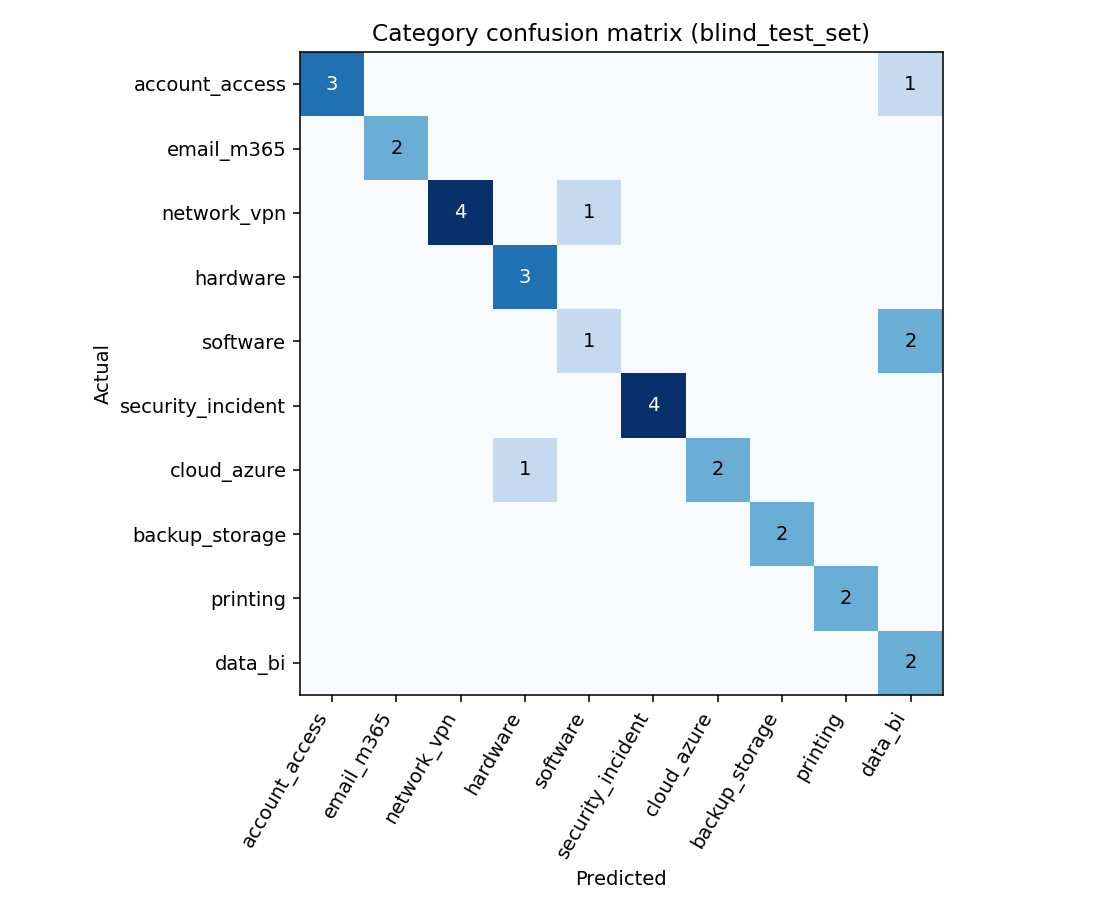

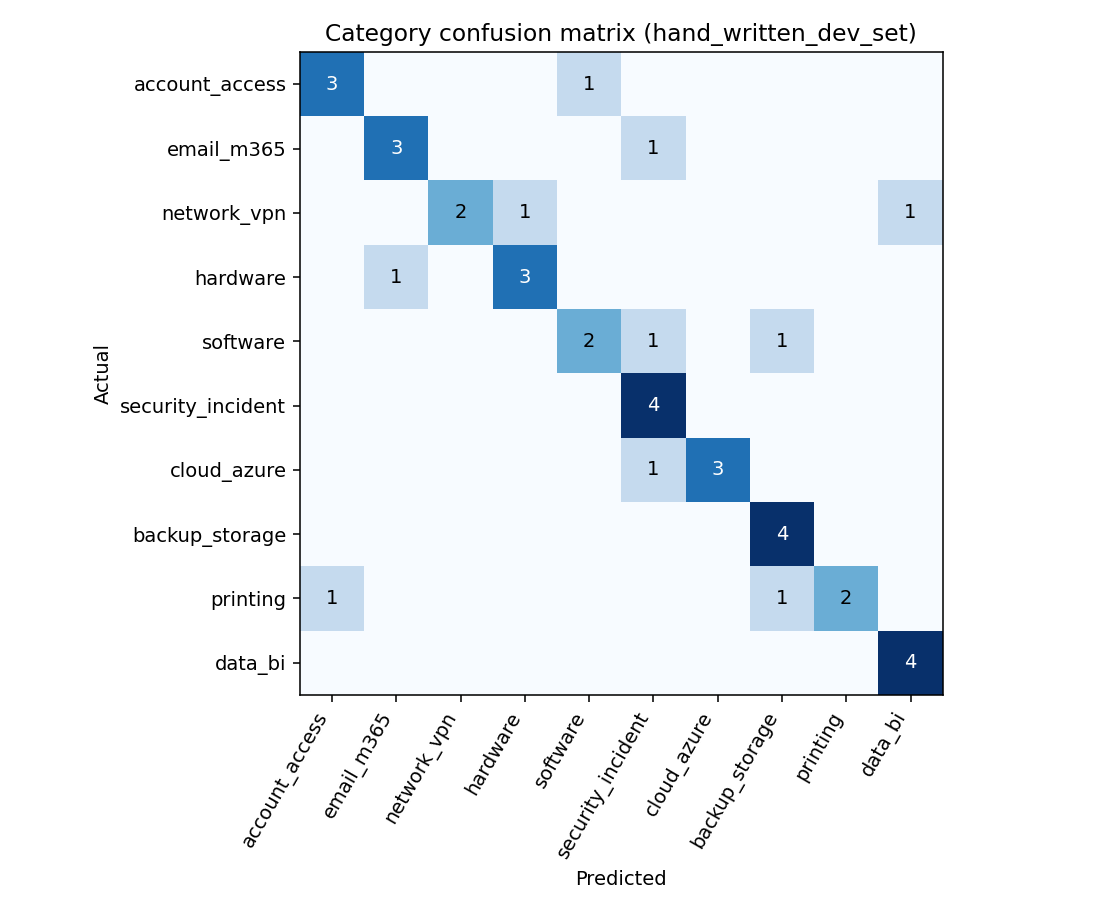

In [7]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('confusion_matrix_*.png')): display(Image(p))

## 5. Try the full pipeline on a few tickets
Set `ANTHROPIC_API_KEY` (Colab Secrets) to let an LLM write the reply, grounded only in retrieved KB articles. Without a key a safe template is used.

In [8]:
import os
# os.environ['ANTHROPIC_API_KEY'] = 'sk-ant-...'   # optional
from kb_and_data import generate
from triage import TicketTriage
model = TicketTriage().fit(generate(3000, seed=42))
tests = ["Our Belfast branch has completely lost internet, around 40 staff cannot work.",
         "Files on the server are renamed .locked and there is a ransom note",
         "Can you install Visio on my laptop? No rush, manager approved.",
         "Something is wrong again, it's not working"]
for t in tests:
    r = model.run(t, use_llm=bool(os.environ.get('ANTHROPIC_API_KEY')))
    print('TICKET  :', t)
    print('RESULT  :', r['category'], f"({r['cat_conf']:.2f})", r['priority'], '->', r['route']['escalate_to'], r['flags'])
    print('KB      :', [h['kb_id'] for h in r['kb']])
    print('REASONS :', r['route']['reasons'])
    print(r['reply']['text'], '\n' + '-'*70)

TICKET  : Our Belfast branch has completely lost internet, around 40 staff cannot work.
RESULT  : network_vpn (0.62) P1 -> Senior engineer / duty manager ['p1_rule_floor']
KB      : ['KB-006', 'KB-005', 'KB-001']
REASONS : ['P1 priority: major incident process']
Hello,

Thanks for getting in touch. Here are the first steps we suggest:
1. Identify scope: one user, one site, or all sites. [KB-006]
2. Check switch and access point status in the monitoring tool. [KB-006]
3. Test DNS and DHCP. [KB-006]
4. Check ISP circuit and failover link. [KB-006]

If this doesn't resolve it, reply and an engineer will pick it up. 
----------------------------------------------------------------------
TICKET  : Files on the server are renamed .locked and there is a ransom note
RESULT  : security_incident (0.61) P1 -> Security Operations ['p1_rule_floor']
KB      : ['KB-012', 'KB-015', 'KB-011']
REASONS : ['Security category: always handled by SOC / security team', 'P1 priority: major incident process']
H